In [102]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

# Loading the Taxis Dataset

In [103]:
df =sns.load_dataset("taxis")

In [104]:
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


# Handling Missing Values

Check for missing values in the dataset and identify columns with missing data.
Impute missing values using appropriate strategies based on the column type.
For columns that are critical and cannot be reasonably imputed, remove rows with missing values to maintain data integrity.

In [105]:
df.shape

(6433, 14)

In [106]:
df.columns

Index(['pickup', 'dropoff', 'passengers', 'distance', 'fare', 'tip', 'tolls',
       'total', 'color', 'payment', 'pickup_zone', 'dropoff_zone',
       'pickup_borough', 'dropoff_borough'],
      dtype='str')

In [107]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null   str           
 11  dropoff_zone     6388 non-null   str           
 12  pickup_borough   6407 non-null   str           
 13  dropoff_borough  6388 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(1), str(6)


In [108]:
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [109]:
miss = df.isnull().sum()
miss[miss>0]

payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [110]:
for i in df.select_dtypes(include="number").columns:
    df[i]=df[i].fillna(df[i].median())

In [111]:
for i in df.select_dtypes(include=["object","category","string"]).columns:
    if df[i].isnull().any() and not df[i].mode().empty:
         df[i]=df[i].fillna(df[i].mode()[0]) 
   

In [112]:
df = df.dropna(subset=["pickup"])
df["pickup"] = pd.to_datetime(df["pickup"], errors="coerce")
df = df.dropna(subset=["pickup"])

In [113]:
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

# Visualizations using Matplotlib/Pandas Plot

Line chart — Fare over time

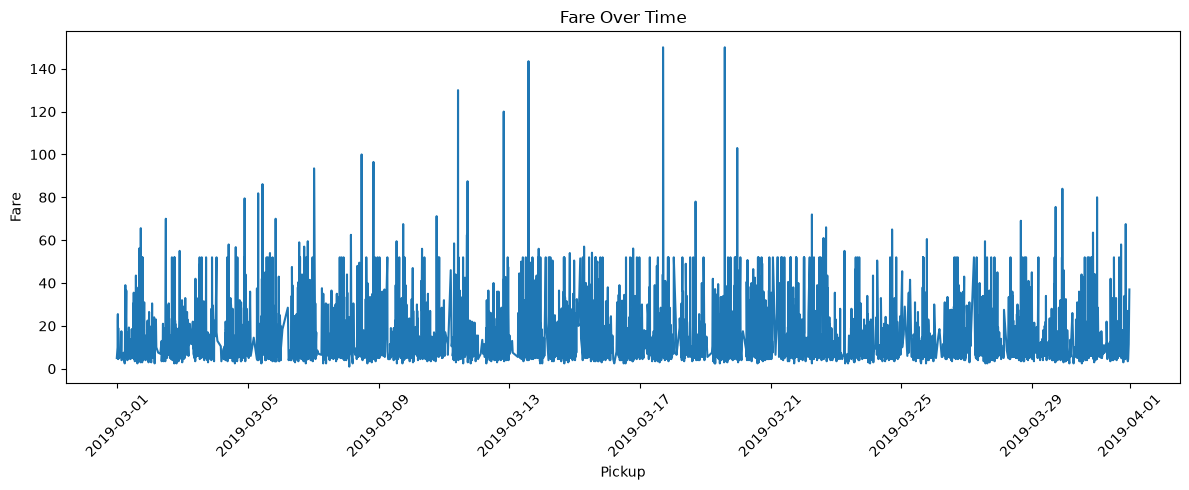

In [114]:
l = df.sort_values("pickup")
plt.figure(figsize=(12, 5))
plt.plot(l["pickup"], l["fare"])
plt.title("Fare Over Time")
plt.xlabel("Pickup")
plt.ylabel("Fare")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Bar chart — Total fare by pickup borough

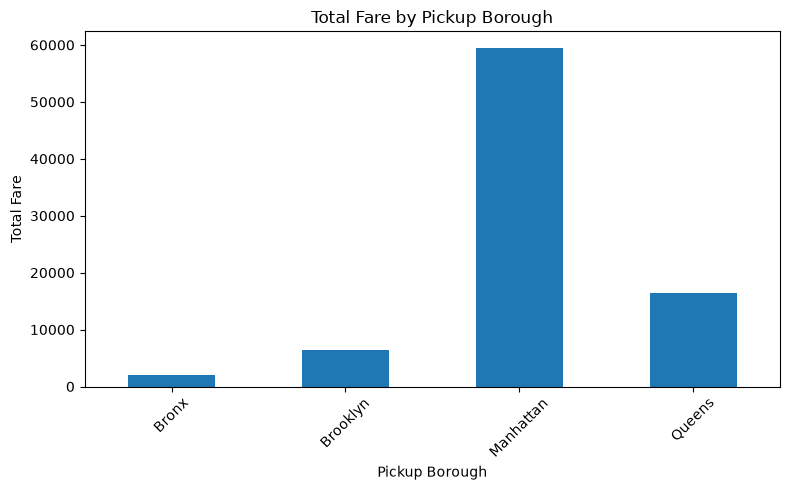

In [115]:
f = df.groupby("pickup_borough")["fare"].sum()

f.plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Fare by Pickup Borough"
)

plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Pie chart — Trips by payment method

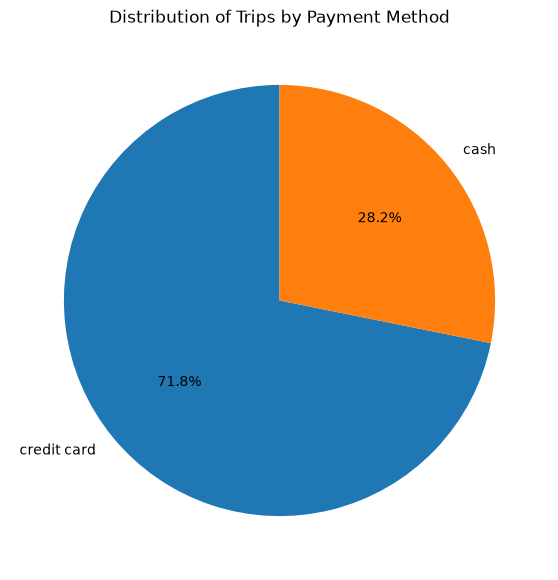

In [116]:
count = df["payment"].value_counts()
plt.figure(figsize=(7, 7))
plt.pie(
    count,
    labels=count.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Trips by Payment Method")
plt.show()

Histogram — Distribution of trip distance

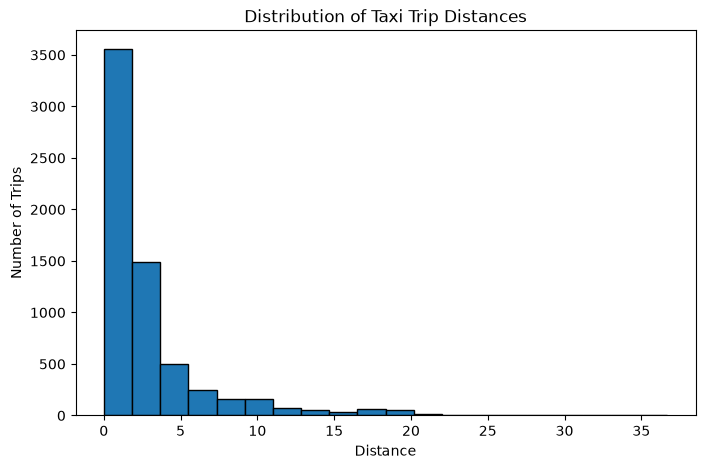

In [117]:
plt.figure(figsize=(8, 5))
plt.hist(df["distance"].dropna(), bins=20, edgecolor="black")
plt.title("Distribution of Taxi Trip Distances")
plt.xlabel("Distance")
plt.ylabel("Number of Trips")
plt.show()

Box plot — Tip by pickup borough

<Figure size 900x500 with 0 Axes>

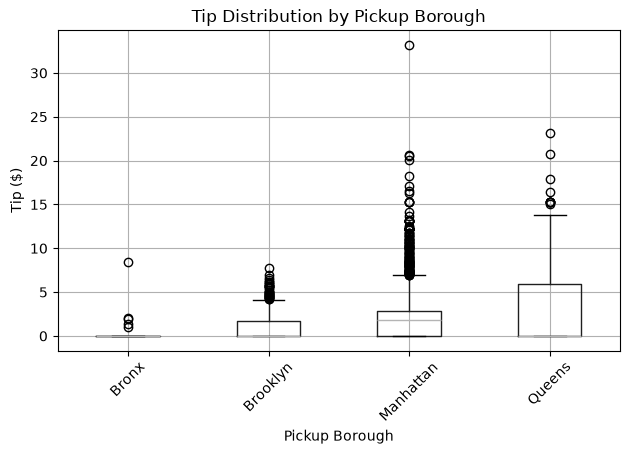

In [118]:
plt.figure(figsize=(9, 5))
df.boxplot(column="tip", by="pickup_borough")
plt.title("Tip Distribution by Pickup Borough")
plt.suptitle("")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Visualizations using Seaborn

Count plot — Number of trips by pickup borough

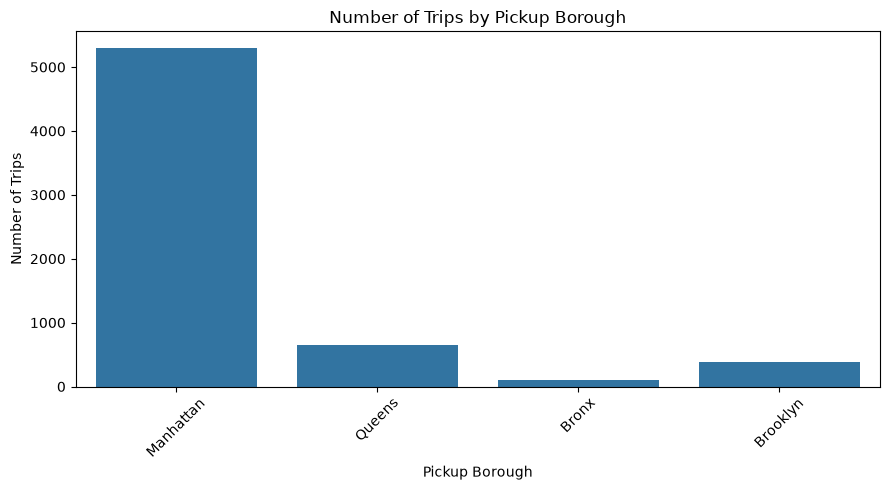

In [119]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="pickup_borough")
plt.title("Number of Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Scatter plot — Distance versus fare

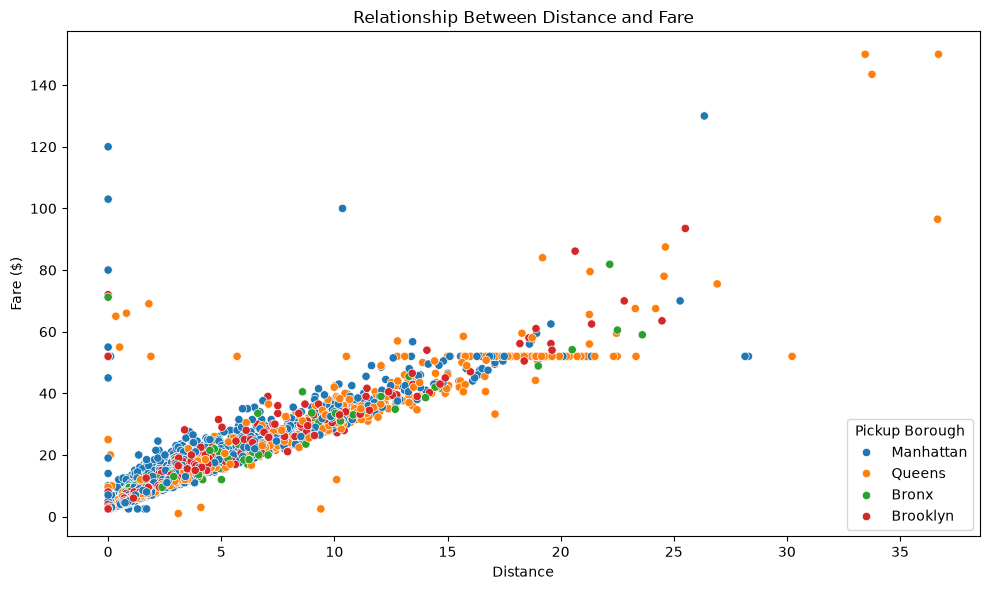

In [120]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="distance",
    y="fare",
    hue="pickup_borough"
)
plt.title("Relationship Between Distance and Fare")
plt.xlabel("Distance")
plt.ylabel("Fare ($)")
plt.legend(title="Pickup Borough")
plt.tight_layout()
plt.show()

Heatmap — Correlation between numerical variables

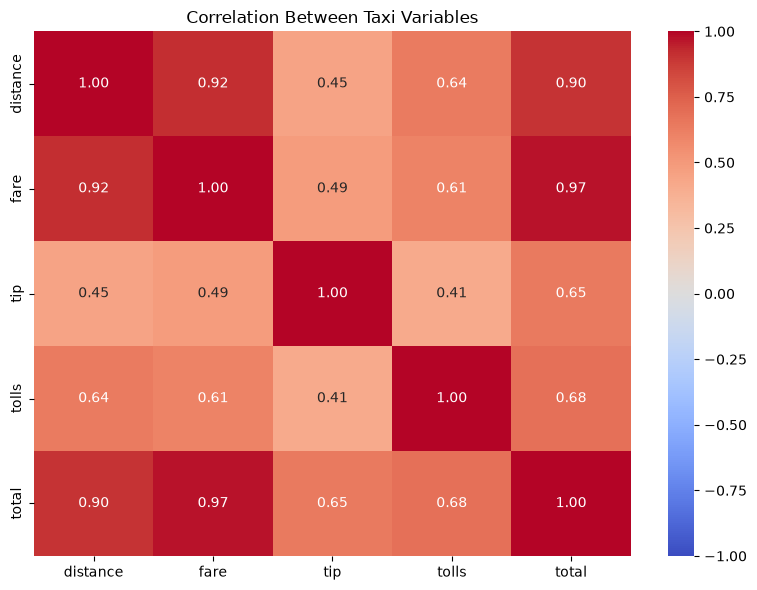

In [121]:
col = ["distance", "fare", "tip", "tolls", "total"]
cm = df[col].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)
plt.title("Correlation Between Taxi Variables")
plt.tight_layout()
plt.show()

Pair plot — Pairwise relationships between variables

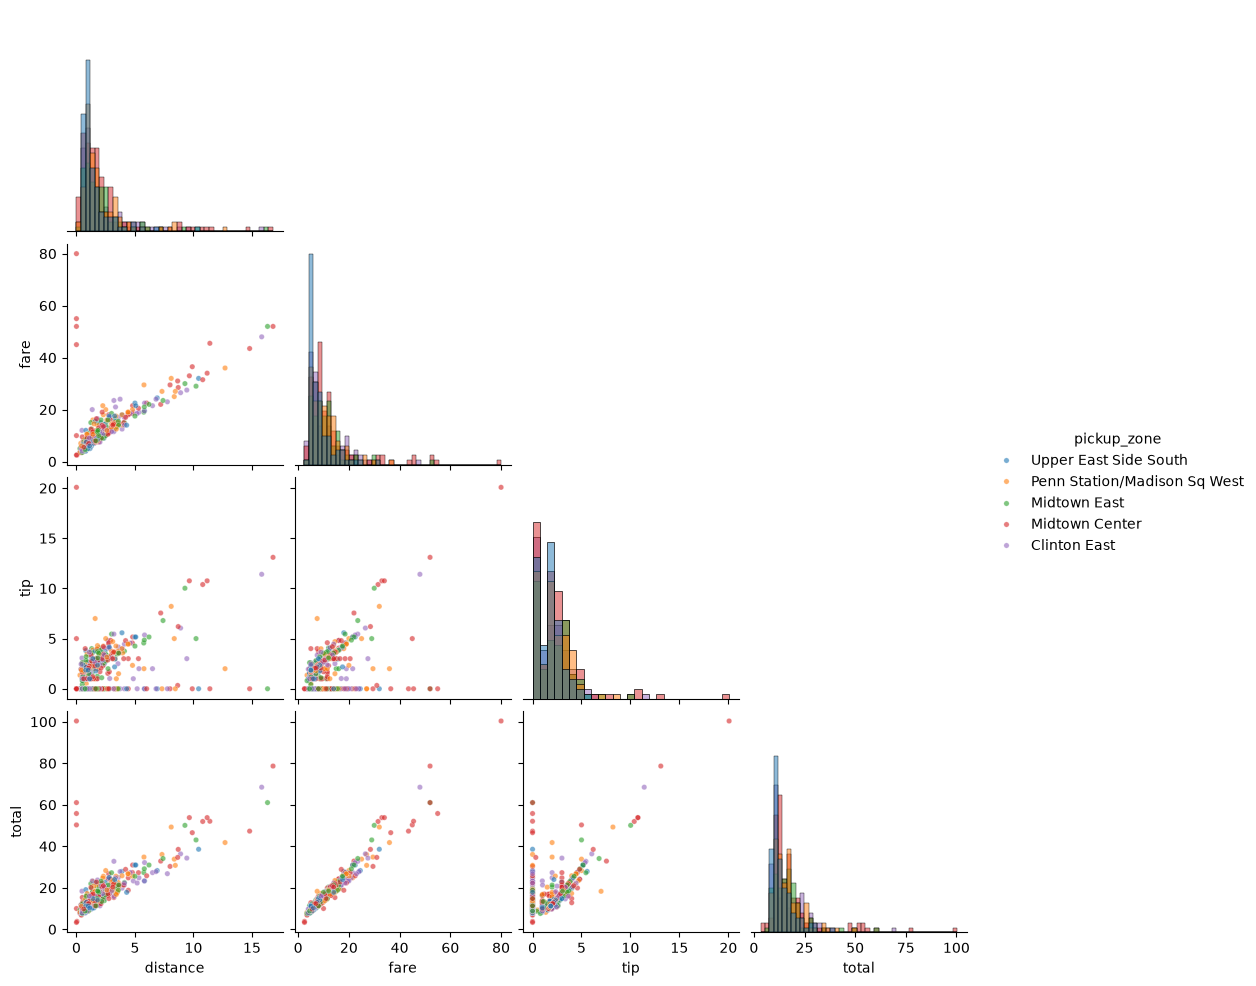

In [122]:
pair_cols = ["distance", "fare", "tip", "total", "pickup_zone"]
pair_df = df[pair_cols].dropna().copy()
top_zones = pair_df["pickup_zone"].value_counts().head(5).index
pair_df = pair_df[pair_df["pickup_zone"].isin(top_zones)]
pair_sample = pair_df.sample(
    n=min(500, len(pair_df)),
    random_state=42
)
sns.pairplot(
    data=pair_sample,
    vars=["distance", "fare", "tip", "total"],
    hue="pickup_zone",
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.6, "s": 15}
)
plt.show()

Violin plot — Fare distribution by payment method

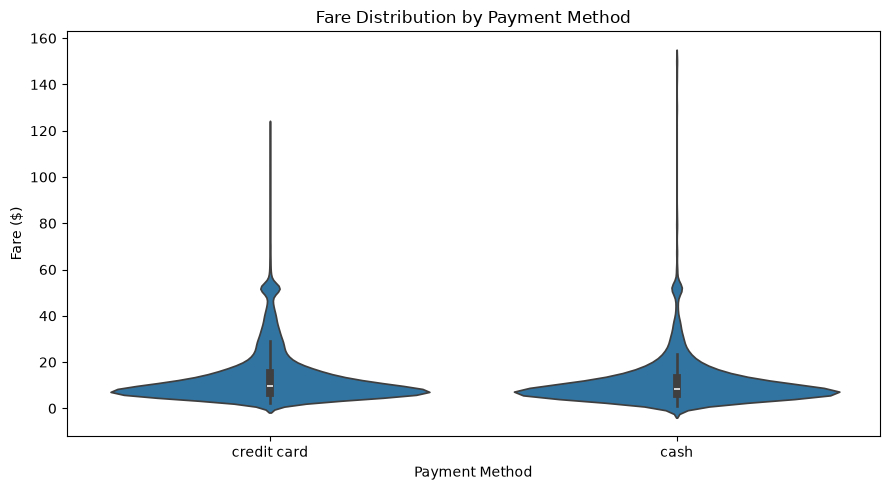

In [123]:
plt.figure(figsize=(9, 5))

sns.violinplot(
    data=df,
    x="payment",
    y="fare"
)

plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare ($)")
plt.tight_layout()
plt.show()